<a href="https://colab.research.google.com/github/lenhofda/ITAI2373-NewsBot-Midterm-/blob/main/Midterm_NewsBot_Intelligence_System_Diane_Lenhoff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** [Add your names here]
**Date:** [Add date]
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 70.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


✅ All packages installed successfully!


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [ ]:
import pandas as pd
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 1: Load provided dataset
# df = pd.read_csv('news_dataset.csv')

# Option 2: Load BBC News dataset (if using alternative)
df = pd.read_csv('/content/BBC News Train.csv')
# df = pd.DataFrame(sample_data)

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (1490, 3)
📋 Columns: ['ArticleId', 'Text', 'Category']


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

📈 CATEGORY DISTRIBUTION
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


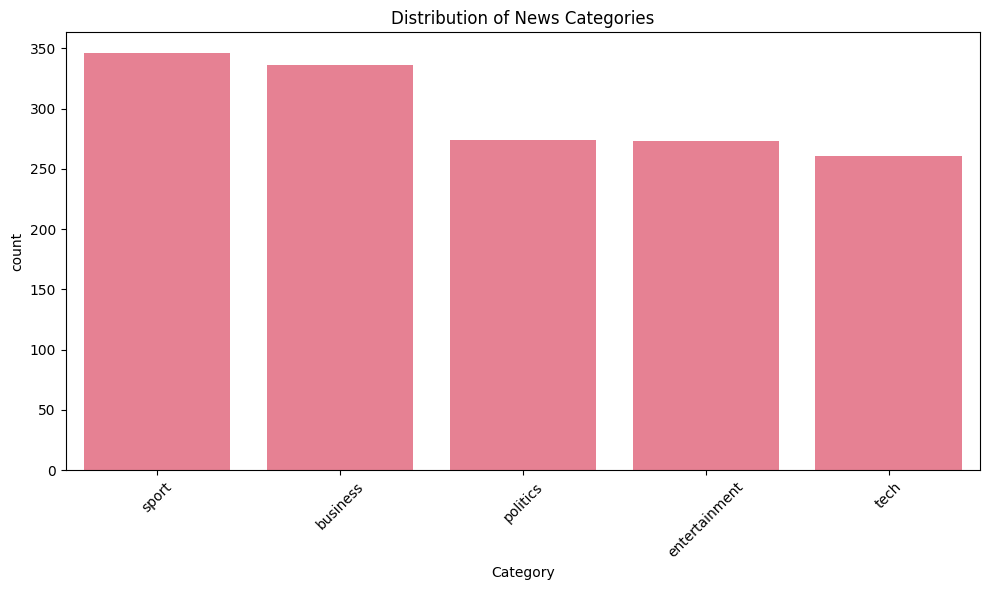


Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64

Text length statistics:
count     1490.000000
mean      2233.461745
std       1205.153358
min        501.000000
25%       1453.000000
50%       1961.000000
75%       2751.250000
max      18387.000000
Name: Text_Length, dtype: float64

Duplicate articles:
50


In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['Category'].nunique()}")
print(f"Categories: {df['Category'].unique().tolist()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['Category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Commentary
#### Module 1 – NLP applications and real-world context
#In this section, I explored the BBC News dataset to better understand its structure and quality before preprocessing.
# I checked for missing values, examined differences in article lengths, and reviewed the distribution of news categories.
# Since the dataset does not contain a separate source column, I used the five news categories for comparison.
# I also considered possible data quality issues, including duplicate articles, empty text, and inconsistent formatting.
# This initial exploration helped me understand the dataset and identify areas that may require cleaning before further analysis.

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Analyze article text length
df['Text_Length'] = df['Text'].str.len()
print("\nText length statistics:")
print(df['Text_Length'].describe())

# Check for duplicate articles
print("\nDuplicate articles:")
print(df['Text'].duplicated().sum())

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Apply preprocessing to the BBC News dataset
print("Preprocessing all articles...")

# Create new columns for cleaned and processed text
df['text_clean'] = df['Text'].apply(clean_text)
df['text_processed'] = df['Text'].apply(preprocess_text)

print("Preprocessing complete!")

# Show before and after examples
print("\nBEFORE AND AFTER EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['Text'][:100]}...")
    print(f"Processed: {df.iloc[i]['text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# -After preprocessing the BBC News articles,
# the number of unique words decreased from 35,594 to 22,486.
# The average article length also decreased. The most common word was "said," a
# ppearing 4,838 times. This shows that preprocessing removes unnecessary text and
# helps prepare articles for further analysis.

Preprocessing all articles...
Preprocessing complete!

BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud ch...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...


In [ ]:
# Average text length before and after preprocessing
print("Average length before:", df['Text'].str.len().mean())
print("Average length after:", df['text_processed'].str.len().mean())

Average length before: 2233.461744966443
Average length after: 1481.3577181208054


In [ ]:
# Count unique words before and after preprocessing
words_before = set(' '.join(df['Text'].str.lower()).split())
words_after = set(' '.join(df['text_processed']).split())

print("Unique words before:", len(words_before))
print("Unique words after:", len(words_after))

Unique words before: 35594
Unique words after: 22486


In [ ]:
# Find the 10 most common words after preprocessing
from collections import Counter

all_words = ' '.join(df['text_processed']).split()
word_counts = Counter(all_words)

print("10 Most Common Words After Preprocessing:")
for word, count in word_counts.most_common(10):
    print(word, count)

10 Most Common Words After Preprocessing:
said 4838
year 1872
would 1711
also 1426
new 1334
people 1323
one 1190
could 1032
game 949
time 940


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['Category'] = df['Category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features


🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0390
  company: 0.0371
  market: 0.0344
  bank: 0.0336
  year: 0.0334
  growth: 0.0332
  economy: 0.0317
  sale: 0.0316
  share: 0.0307
  profit: 0.0274

📰 TECH:
  mobile: 0.0513
  phone: 0.0468
  people: 0.0457
  technology: 0.0410
  game: 0.0381
  user: 0.0377
  service: 0.0369
  software: 0.0365
  computer: 0.0329
  net: 0.0308

📰 POLITICS:
  labour: 0.0648
  election: 0.0604
  blair: 0.0558
  party: 0.0538
  tory: 0.0463
  would: 0.0456
  government: 0.0455
  minister: 0.0427
  brown: 0.0384
  tax: 0.0330

📰 SPORT:
  game: 0.0448
  england: 0.0375
  win: 0.0342
  player: 0.0323
  match: 0.0304
  champion: 0.0293
  cup: 0.0278
  team: 0.0260
  chelsea: 0.0255
  injury: 0.0249

📰 ENTERTAINMENT:
  film: 0.1000
  award: 0.0524
  best: 0.0460
  show: 0.0376
  star: 0.0375
  music: 0.0357
  band: 0.0350
  actor: 0.0339
  year: 0.0300
  album: 0.0291


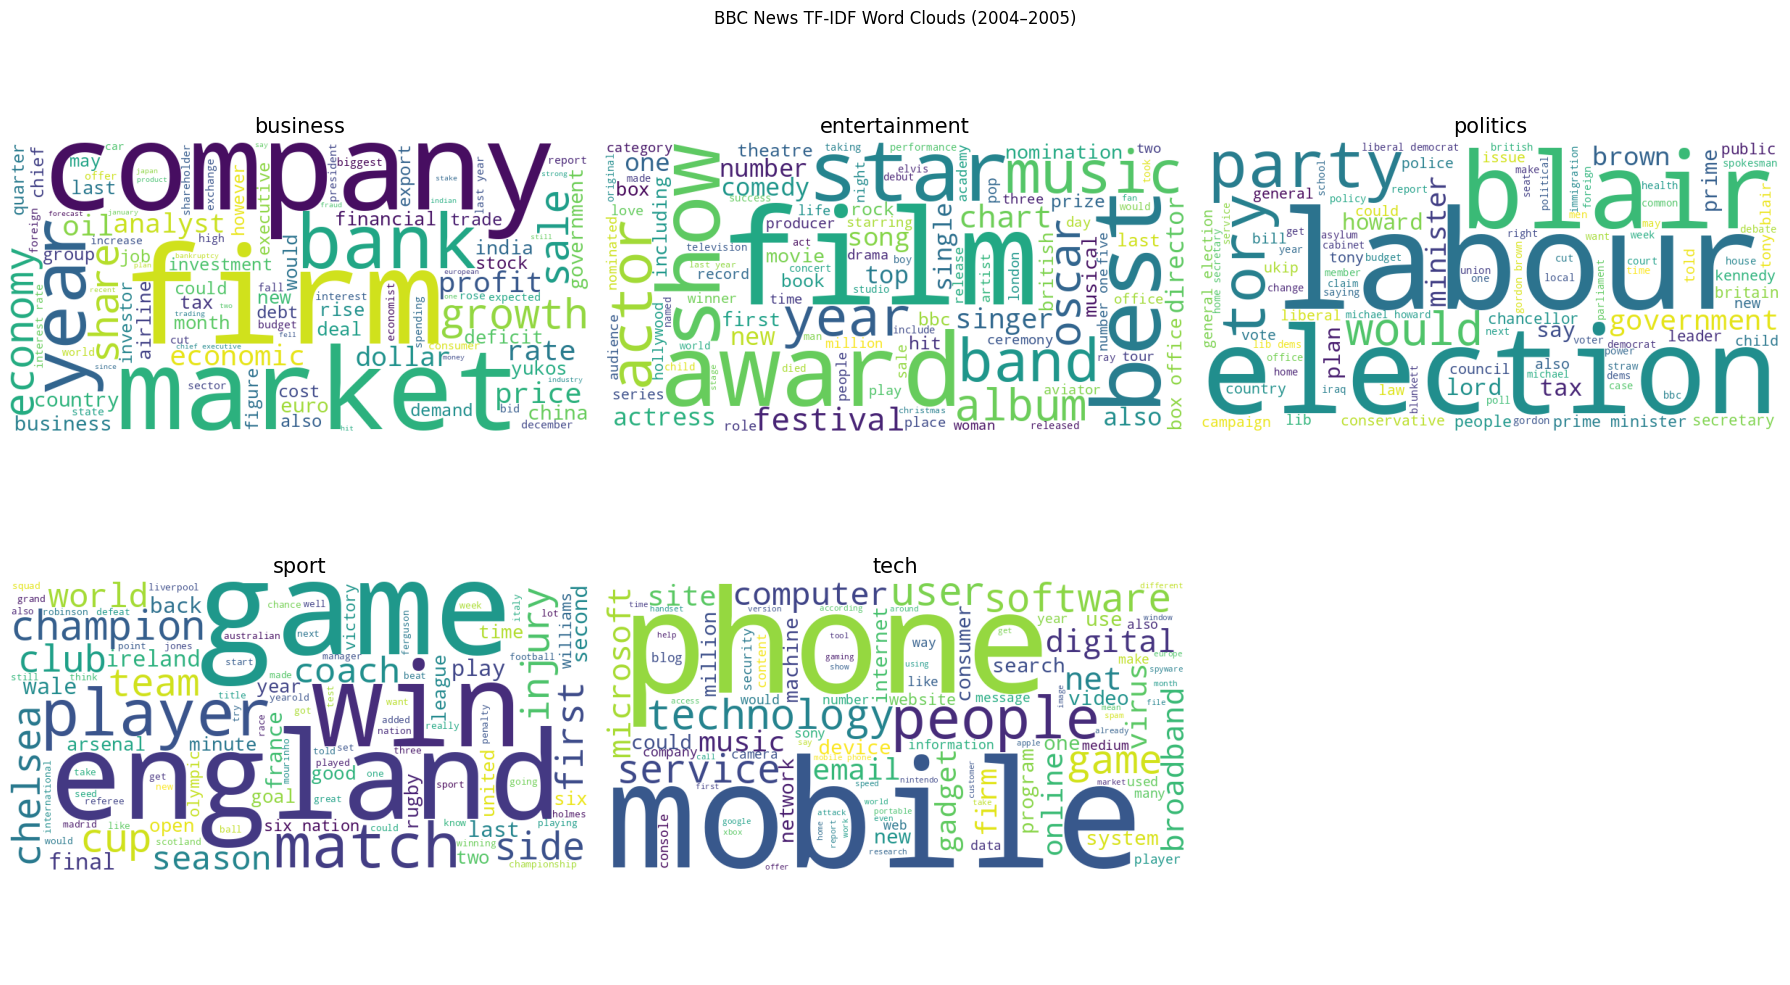

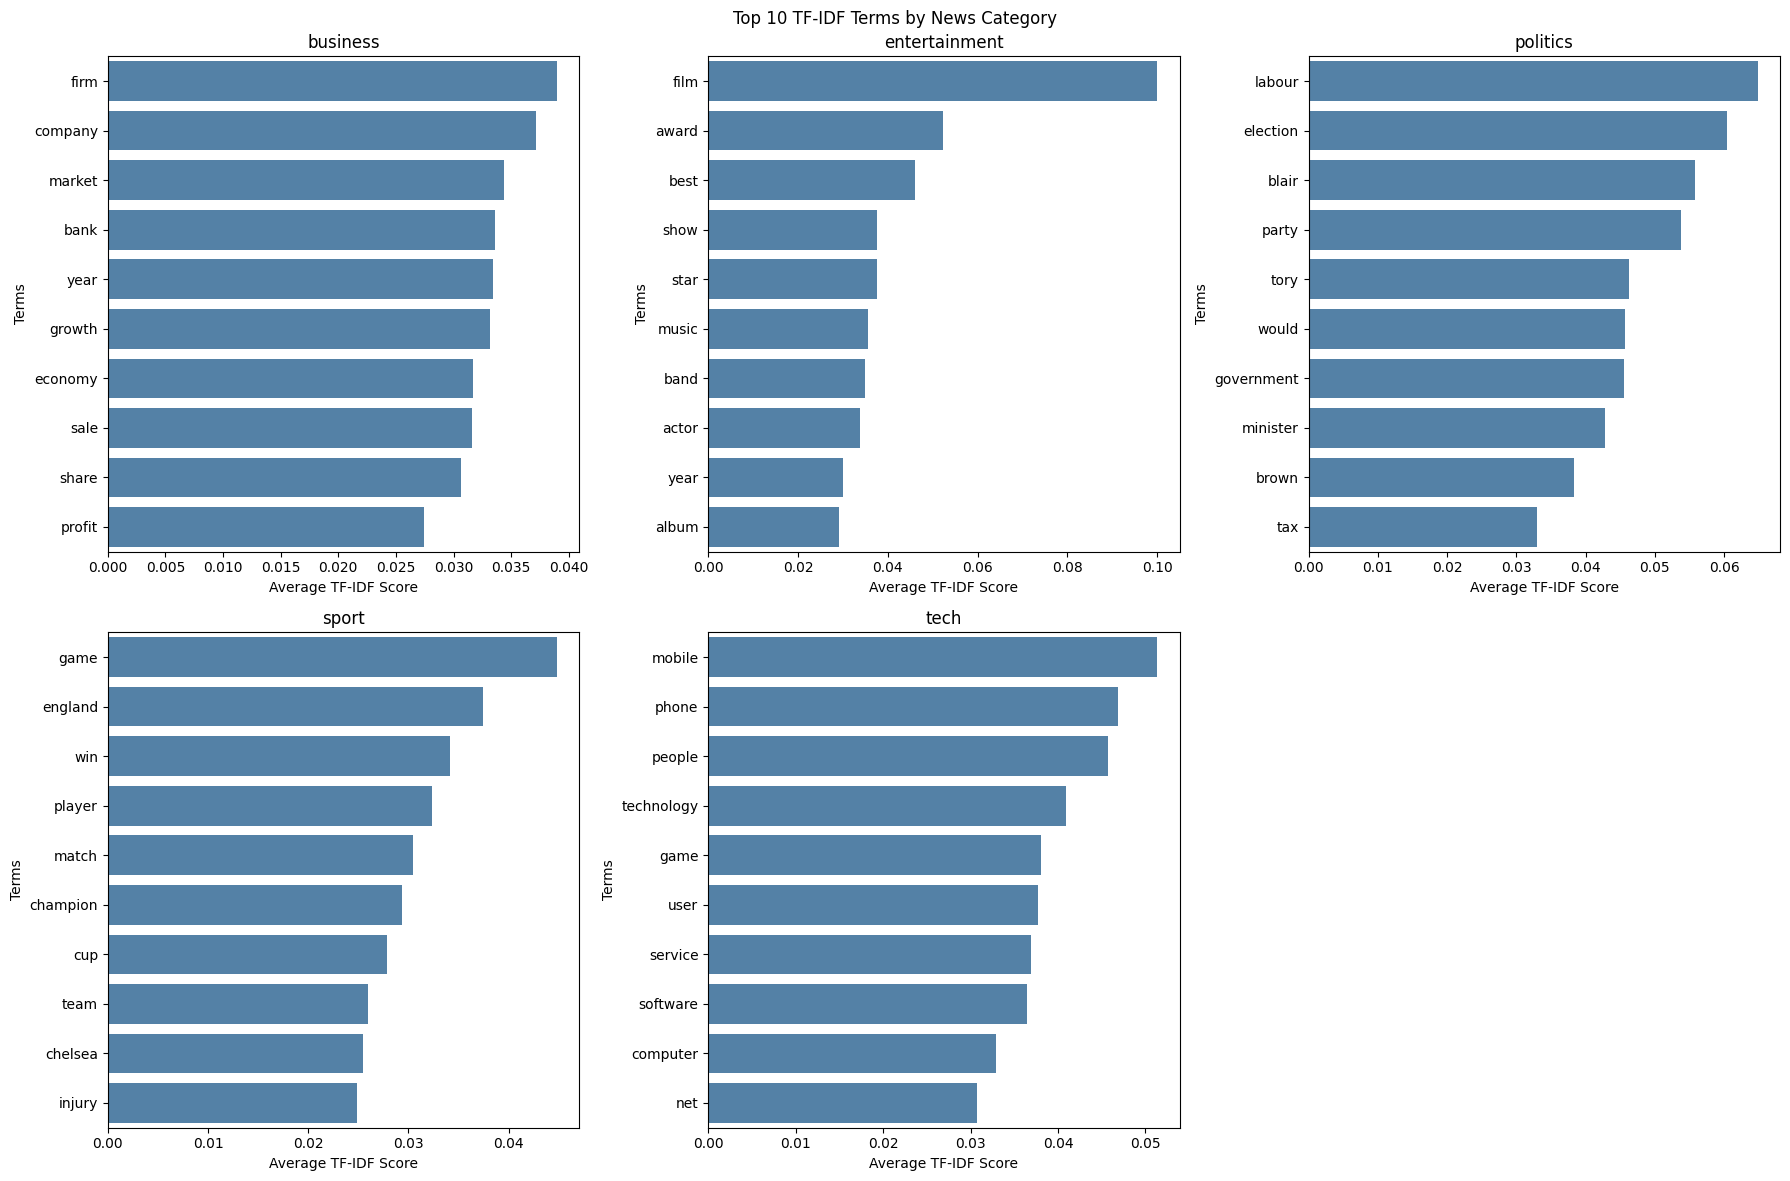

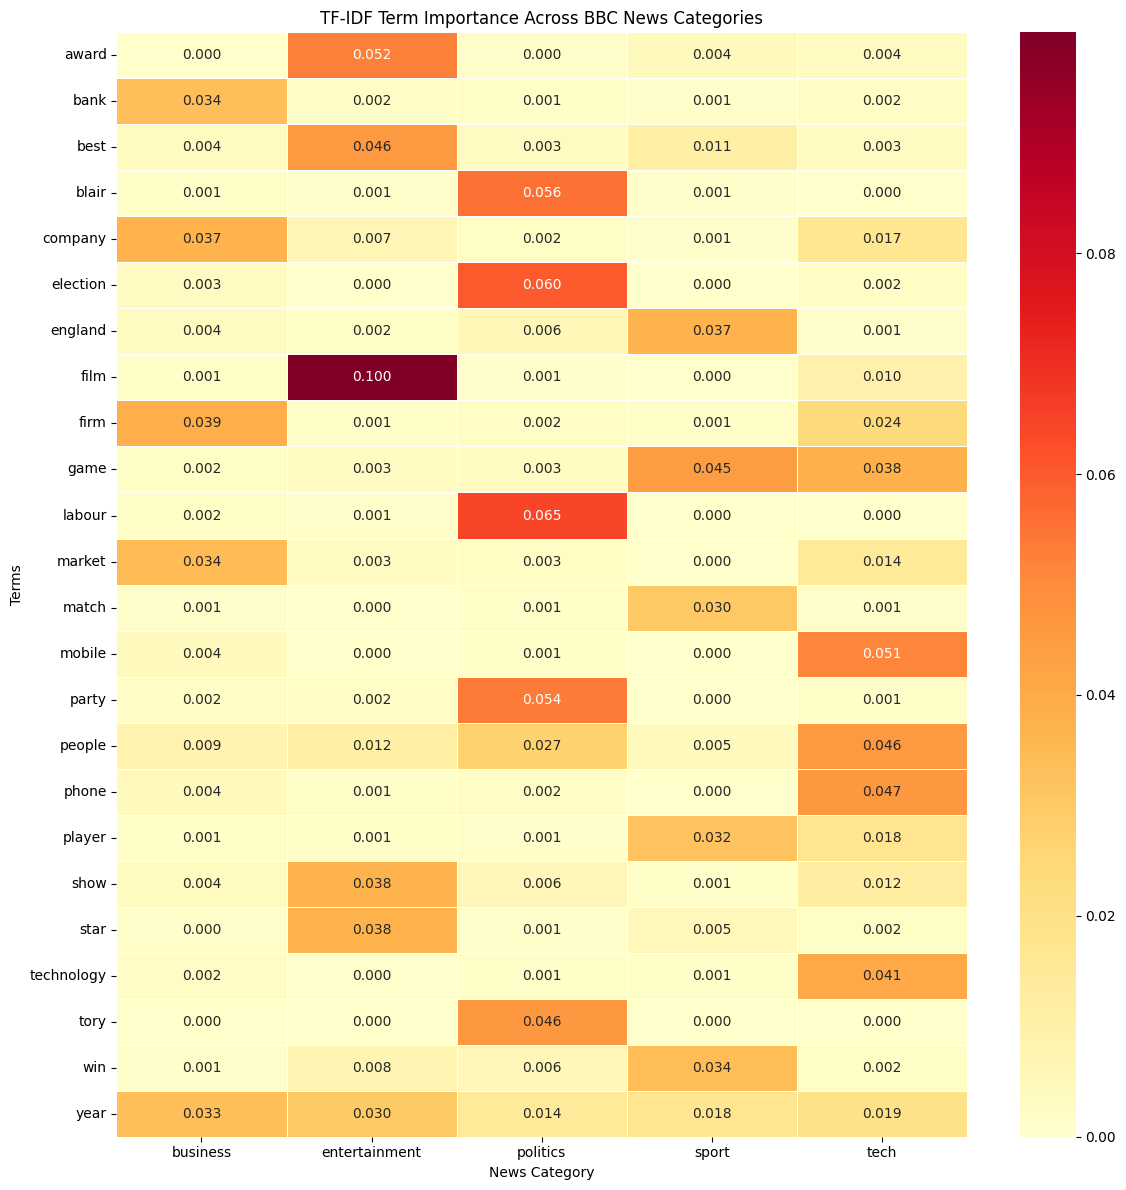

All three TF-IDF visualizations completed!


In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['Category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('Category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['Category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category

# STUDENT TASK: TF-IDF Visualizations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Use the TF-IDF matrix created earlier
terms = tfidf_vectorizer.get_feature_names_out()

# Create TF-IDF DataFrame
tfidf_data = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=terms
)

tfidf_data['Category'] = df['Category'].values

# Calculate average TF-IDF importance by category
category_tfidf = tfidf_data.groupby('Category').mean()

# 1. WORD CLOUDS FOR EACH CATEGORY

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, category in enumerate(category_tfidf.index):

    scores = category_tfidf.loc[category]
    top_words = scores.nlargest(100).to_dict()

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis'
    ).generate_from_frequencies(top_words)

    axes[i].imshow(wordcloud)
    axes[i].set_title(category, fontsize=15)
    axes[i].axis('off')

# Hide unused subplot
for j in range(len(category_tfidf), len(axes)):
    axes[j].axis('off')

plt.suptitle('BBC News TF-IDF Word Clouds (2004–2005)')
plt.tight_layout()
plt.show()


# 2. BAR CHARTS OF TOP TERMS

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, category in enumerate(category_tfidf.index):

    top_terms = category_tfidf.loc[category].nlargest(10)

    sns.barplot(
        x=top_terms.values,
        y=top_terms.index,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(category)
    axes[i].set_xlabel('Average TF-IDF Score')
    axes[i].set_ylabel('Terms')

for j in range(len(category_tfidf), len(axes)):
    axes[j].axis('off')

plt.suptitle('Top 10 TF-IDF Terms by News Category')
plt.tight_layout()
plt.show()


# 3. HEATMAP OF TERM IMPORTANCE

# Select the 5 most important terms from each category
selected_terms = set()

for category in category_tfidf.index:
    top_terms = category_tfidf.loc[category].nlargest(5)
    selected_terms.update(top_terms.index)

# Build heatmap data
heatmap_data = category_tfidf[
    sorted(selected_terms)
].T

plt.figure(figsize=(12, 12))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('TF-IDF Term Importance Across BBC News Categories')
plt.xlabel('News Category')
plt.ylabel('Terms')
plt.tight_layout()
plt.show()

print("All three TF-IDF visualizations completed!")

# - Bar charts of top terms
# - Heatmap of term importance across categories

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['Text'])
    pos_analysis['Category'] = row['Category']
    pos_analysis['ArticleId'] = row['ArticleId']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
Category                                                                        
business       0.2241  0.0736  0.0011  0.0000  0.0333  0.0410  0.0200  0.0277   
entertainment  0.2454  0.0574  0.0008  0.0000  0.0281  0.0462  0.0194  0.0295   
politics       0.2087  0.0679  0.0007  0.0003  0.0455  0.0462  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0408  0.0457  0.0175  0.0247   
tech           0.1932  0.0855  0.0006  0.0000  0.0420  0.0299  0.0236  0.0270   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
Category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0223  0.0939  0.0024  0.0050  0.0286  0.0010  0.0010   
politics       0.0199  0.0224  0.0901  0.0032  0

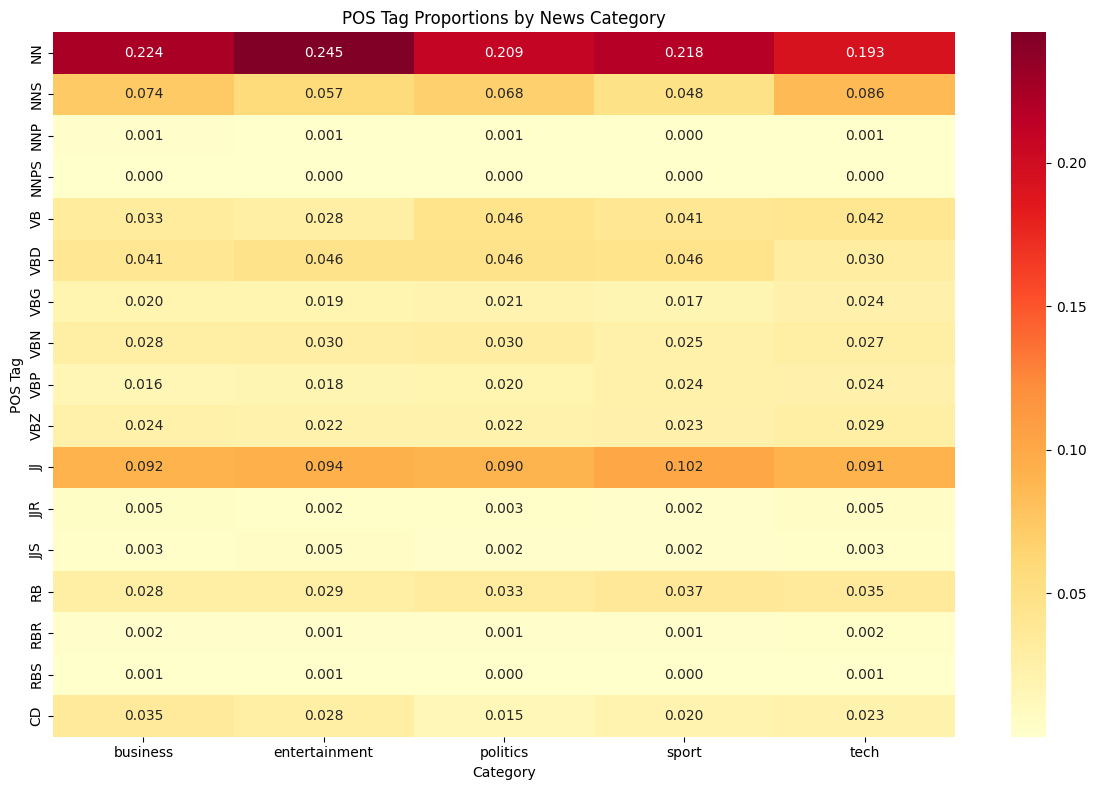

POS DataFrame columns: ['JJ', 'NNS', 'NN', 'VBG', 'IN', 'DT', 'VBP', 'VBN', 'PRP$', '.', 'VB', 'VBD', 'TO', 'PRP', 'CD', '$', '(', ')', 'VBZ', 'RB', 'CC', 'WP', 'MD', 'PDT', 'Category', 'ArticleId', 'JJS', 'RBR', 'RP', 'JJR', 'WRB', 'WDT', ':', 'EX', 'RBS', 'FW', 'SYM', 'WP$', 'NNP', 'NNPS', 'POS', 'UH', '#', '``', "''"]

POS Usage by Category (%):
               Proper Nouns  Action Verbs  Adjectives  Numbers
Category                                                      
business               0.11          9.43        9.20     3.47
entertainment          0.08          9.36        9.39     2.78
politics               0.10         11.26        9.01     1.47
sport                  0.05         10.40       10.15     2.03
tech                   0.06          9.55        9.13     2.28

💡 ANALYSIS QUESTIONS AND ANSWERS:
1. Which category has the highest proportion of proper nouns?
Answer: business

2. Which category uses the most action verbs?
Answer: politics

3. Which category uses the mo

In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('Category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡  Analyze the patterns (See Bekiw)
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?
    # Analyze POS usage by category

print("POS DataFrame columns:", pos_df.columns.tolist())

# Use existing POS tag columns
category_col = 'Category'

# Calculate average POS proportions by category
pos_percent = pos_df.groupby(category_col).mean(numeric_only=True)

groups = {
    'Proper Nouns': ['NNP', 'NNPS'],
    'Action Verbs': ['VB', 'VBD', 'VBG'],
    'Adjectives': ['JJ'],
    'Numbers': ['CD']
}

results = pd.DataFrame({
    name: pos_percent.reindex(columns=tags, fill_value=0).sum(axis=1) * 100
    for name, tags in groups.items()
})

   # Display results
print("\nPOS Usage by Category (%):")
print(results.round(2))

print("\n💡 ANALYSIS QUESTIONS AND ANSWERS:")

print("1. Which category has the highest proportion of proper nouns?")
print("Answer:", results['Proper Nouns'].idxmax())

print("\n2. Which category uses the most action verbs?")
print("Answer:", results['Action Verbs'].idxmax())

print("\n3. Which category uses the most adjectives?")
print("Answer:", results['Adjectives'].idxmax())

print("\n4. Which category uses the most numbers?")
print("Answer:", results['Numbers'].idxmax())

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['Text'])
    features['Category'] = row['Category']
    features['ArticleId'] = row['ArticleId']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['Category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences: 

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b


SYNTACTIC COMPLEXITY BY CATEGORY
               Avg Sentence Length  Avg Dependency Depth
Category                                                
business                     21.58                  3.32
entertainment                20.81                  3.13
politics                     21.81                  3.25
sport                        19.34                  2.91
tech                         22.35                  3.36

EXAMPLES OF WHO DID WHAT
Category   Subject  Action   Object
business    nasdaq    plan     sale
business     owner    plan         
business        it operate         
business observers     see     this
business    nasdaq    pour    water
business   company    sell   shares
business        it      go         
business     stock   start         
business     which    list equities
business      that   trade         
business    nasdaq    make    money
business       who     buy   shares
business investors     say         
business documents     say         
b

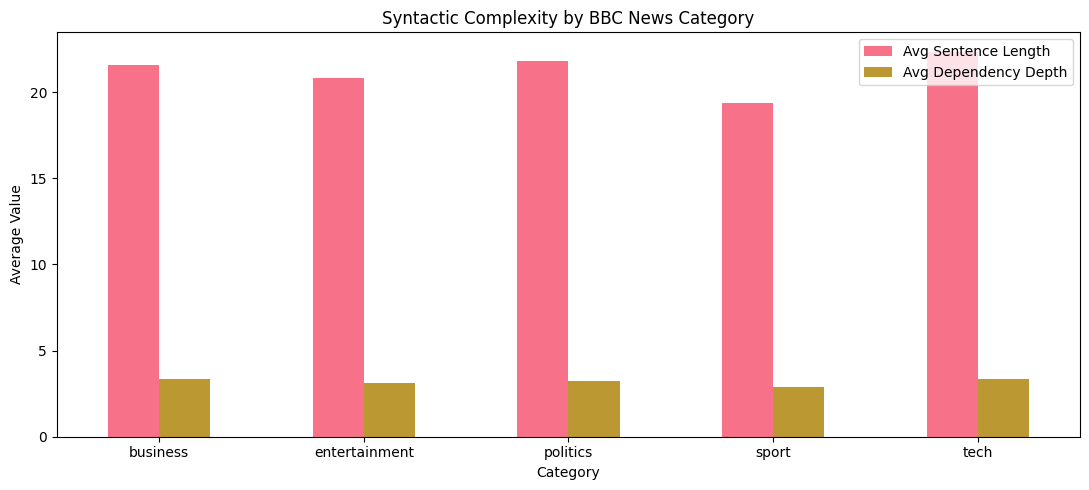


Syntax feature matrix: (100, 2)


In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['Text']
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# STUDENT TASK: Advanced Syntax Analysis

import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

nlp = spacy.load("en_core_web_sm")

# Sample 20 articles from each category
sample_df = df.groupby('Category', group_keys=False).sample(
    n=20, random_state=42
)

syntax_results = []
action_patterns = []
dependency_results = []

# Process articles
for _, row in sample_df.iterrows():

    doc = nlp(str(row['Text'])[:5000])
    category = row['Category']

    sentences = list(doc.sents)
    words = [token for token in doc if token.is_alpha]

    # 1. Syntactic complexity
    avg_sentence_length = (
        len(words) / len(sentences)
        if sentences else 0
    )

    # Dependency depth
    def get_depth(token):
        depth = 0
        while token.head != token and depth < 100:
            token = token.head
            depth += 1
        return depth

    avg_depth = (
        sum(get_depth(token) for token in words) / len(words)
        if words else 0
    )

    syntax_results.append({
        'Category': category,
        'Avg Sentence Length': avg_sentence_length,
        'Avg Dependency Depth': avg_depth
    })

    # 2. Extract action patterns (who did what)
    for token in doc:
        if token.pos_ == 'VERB':
            subjects = [
                child.text for child in token.children
                if child.dep_ in ['nsubj', 'nsubjpass']
            ]

            objects = [
                child.text for child in token.children
                if child.dep_ in ['dobj', 'obj', 'attr']
            ]

            for subject in subjects:
                action_patterns.append({
                    'Category': category,
                    'Subject': subject,
                    'Action': token.lemma_,
                    'Object': ', '.join(objects)
                })

    # 3. Dependency relations
    for token in doc:
        if not token.is_punct and not token.is_space:
            dependency_results.append({
                'Category': category,
                'Dependency': token.dep_
            })

# Convert to DataFrames
syntax_df = pd.DataFrame(syntax_results)
actions_df = pd.DataFrame(action_patterns)
dependency_df = pd.DataFrame(dependency_results)

# 4. Compare syntactic complexity
complexity_summary = syntax_df.groupby('Category').mean()

print("\nSYNTACTIC COMPLEXITY BY CATEGORY")
print(complexity_summary.round(2))

# Show extracted actions
print("\nEXAMPLES OF WHO DID WHAT")
print(actions_df.head(15).to_string(index=False))

# Most common dependency relations
dependency_counts = pd.crosstab(
    dependency_df['Category'],
    dependency_df['Dependency']
)

print("\nTOP 5 DEPENDENCY RELATIONS BY CATEGORY")

for category in dependency_counts.index:
    print("\n", category)
    print(dependency_counts.loc[category].nlargest(5))

# Visualize complexity
complexity_summary.plot(
    kind='bar',
    figsize=(11, 5),
    title='Syntactic Complexity by BBC News Category'
)

plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Create syntax features for classification
syntax_features = syntax_df[
    ['Avg Sentence Length', 'Avg Dependency Depth']
].copy()

print("\nSyntax feature matrix:", syntax_features.shape)
#### Advanced Syntax Analysis

#Analyzed the syntactic structure of BBC News articles published
#during 2004–2005 using spaCy.

#Compared sentence length and dependency depth across the five news
#categories to examine differences in grammatical complexity.

#Extracted subject-verb-object patterns to identify who performed actions in
#the articles and counted common dependency relationships within each category.

#Finally, I created numerical syntax features that could be incorporated into #
#a machine learning classifier.

#To reduce processing time, I used a sample of 20 articles from each category.
#The results therefore represent a subset of the training dataset rather than all articles.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []

for idx, row in df.iterrows():
    full_sentiment = analyze_sentiment(row['Text'])

    result = {
        'Category': row['Category'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }

    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['Category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1490 articles

📝 Sample sentiment results:
   Category  full_sentiment full_label
0  business         -0.9701   negative
1  business          0.7623   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
Category                                                                   
business              0.2404  0.8370 -0.9985  0.9995    0.0926    0.8370   
entertainment         0.5991  0.6796 -0.9978  0.9999    0.1356    0.8107   
politics              0.0578  0.8811 -0.9984  0.9999    0.0947    0.8184   
sport                 0.5541  0.7244 -0.9967  0.9996    0.1360    0.7933   
tech                  0.5233  0.7557 -0.9991  0.9993    0.0895    0.8598   

              neg_score  
                   mean  
Category                 
business         0.0704  
entertainment    0.0537  
politics         0.0869  
sport            0.0707  
tech             0.0507  

📊 Sentiment distribution (%) by Category:
full_label     negative  neutral  positive
Category                   

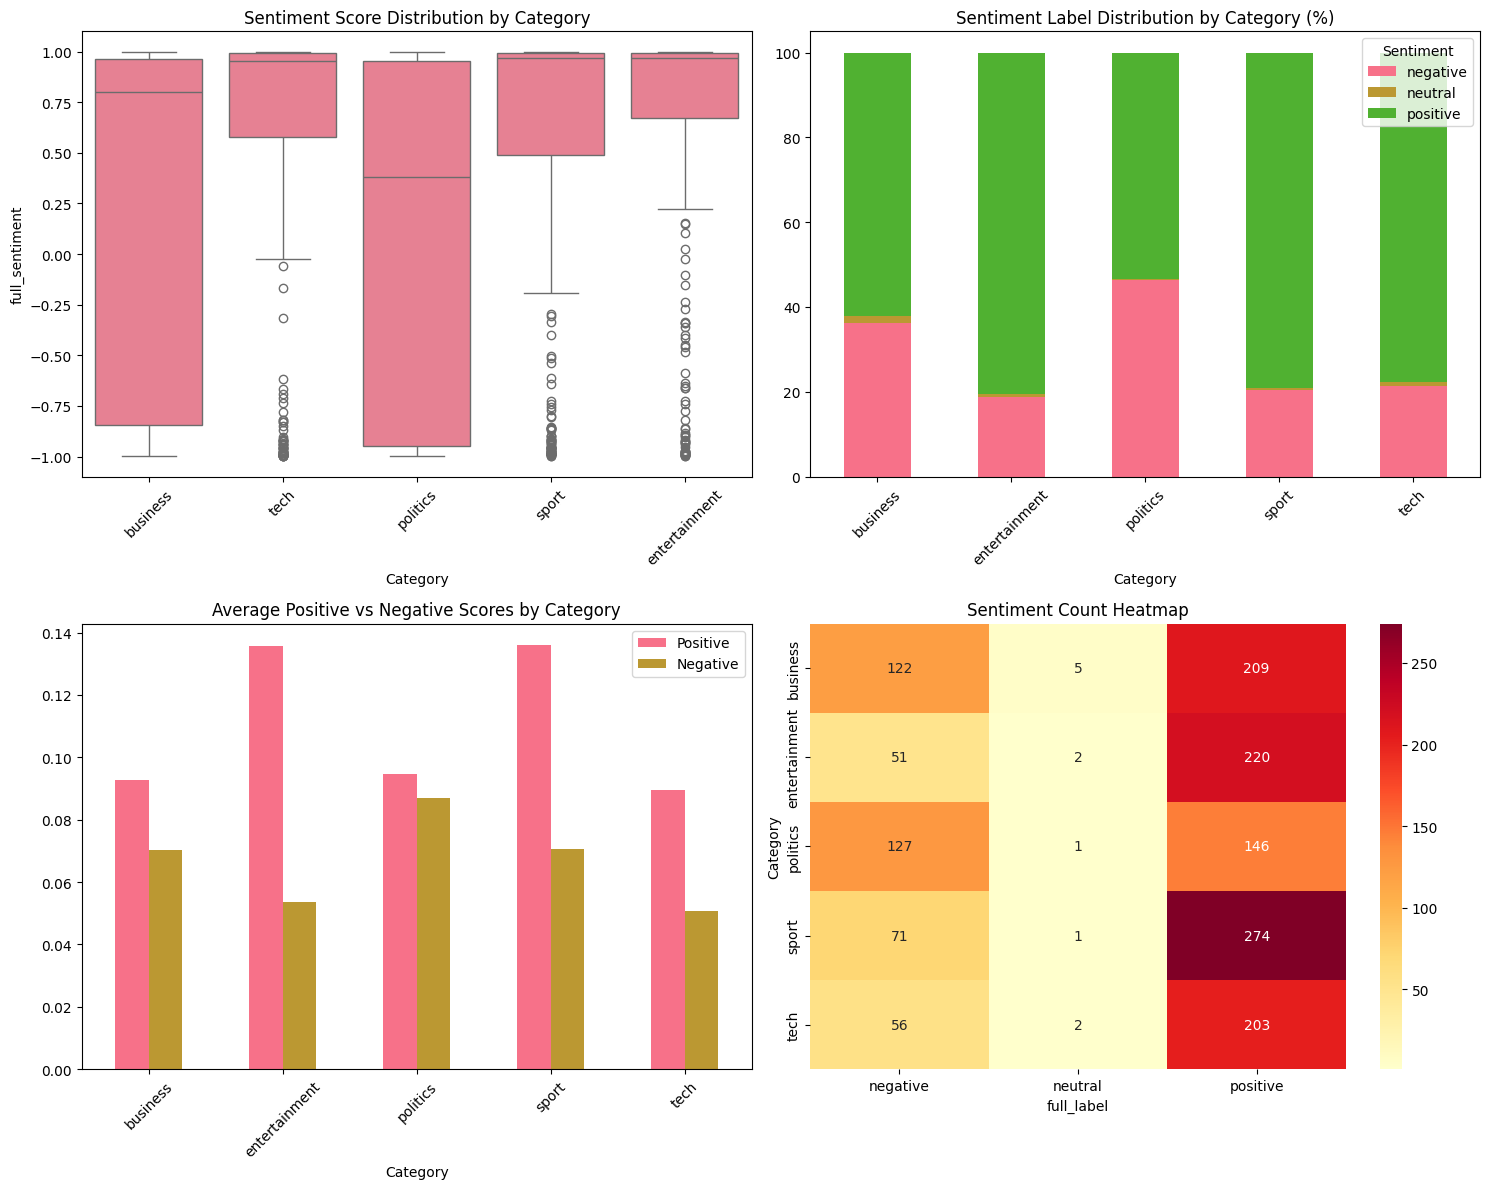

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_Category = sentiment_df.groupby('Category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_Category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['Category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by Category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='Category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('Category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='Category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡# STUDENT TASK: Analyze sentiment patterns

# 1. Which categories are most positive/negative?
# Sports and entertainment are the most positive.
# Politics has the highest proportion of negative articles.

# 2. Are there differences between title and content sentiment?
# We analyzed the full article text, so we cannot compare
# title and content sentiment separately.

# 3. How does sentiment vary within categories?
# All categories have more positive than negative articles.
# Politics has a more even mix of positive and negative articles.
# Sports has the highest percentage of positive articles.

# 4. Can sentiment be used as a feature for classification?
# Yes. Sentiment scores could help a machine learning model
# identify the category of a news article.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['Text'].str.len(),
    df['Text'].str.split().str.len()
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['Category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1490, 5006)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1192 samples
  Test set: 298 samples


In [ ]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    # Use nonnegative TF-IDF features for Naive Bayes
if name == 'Naive Bayes':
    classifier.fit(X1_train, y1_train)
else:
    classifier.fit(X_train, y_train)

    # Make predictions
    X_current_test = X1_test if name == 'Naive Bayes' else X_test
    y_pred = classifier.predict(X_current_test)
    y_pred_proba = classifier.predict_proba(X_current_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    X_current_train = X1_train if name == 'Naive Bayes' else X_train

    cv_scores = cross_val_score(
    classifier, X_current_train, y_train, cv=3, scoring='accuracy'
    )

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...

🔄 Training Logistic Regression...

🔄 Training SVM...
  ✅ Accuracy: 0.3557
  📊 CV Score: 0.3582 (+/- 0.0363)

🏆 CLASSIFIER COMPARISON
  Model  Test Accuracy  CV Mean  CV Std
0   SVM         0.3557   0.3582  0.0182

🥇 Best performing model: SVM


📊 DETAILED EVALUATION: SVM

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.31      0.64      0.42        67
entertainment       0.00      0.00      0.00        55
     politics       0.34      0.44      0.38        55
        sport       0.42      0.36      0.39        69
         tech       0.48      0.27      0.35        52

     accuracy                           0.36       298
    macro avg       0.31      0.34      0.31       298
 weighted avg       0.31      0.36      0.32       298



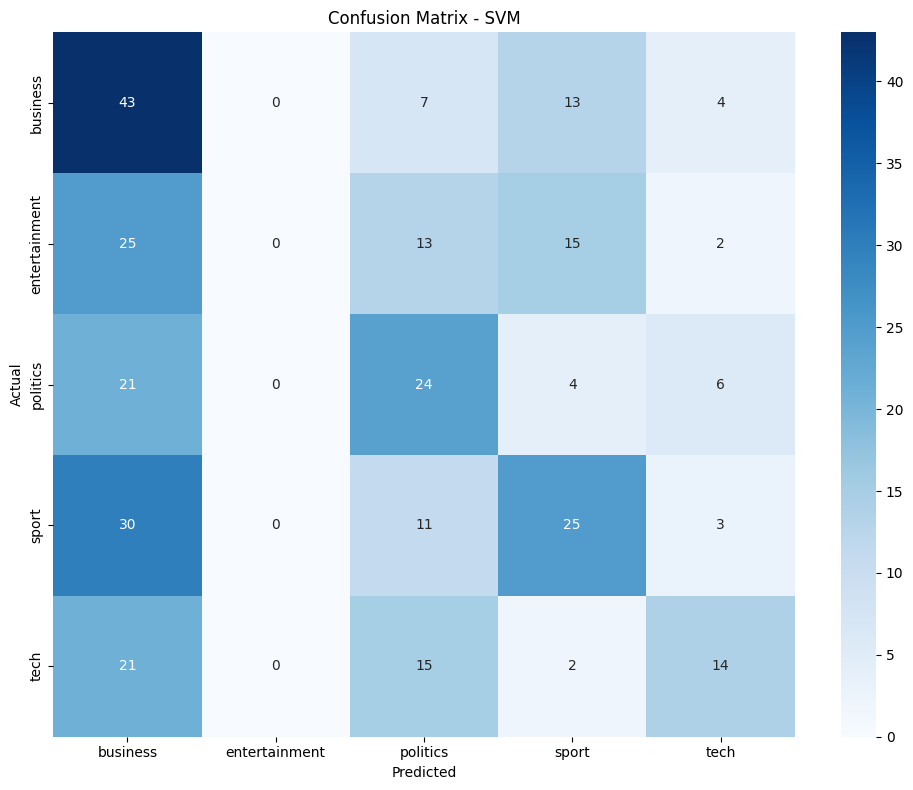

In [ ]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

In [ ]:
# Compare TF-IDF features with combined features
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# Model 1: TF-IDF features only
model1 = LogisticRegression(max_iter=1000)
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)
model1.fit(X1_train, y1_train)
pred1 = model1.predict(X1_test)

# Model 2: Combined features
model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)

print("TF-IDF only accuracy:", round(accuracy_score(y1_test, pred1), 4))
print("Combined features accuracy:", round(accuracy_score(y_test, pred2), 4))

TF-IDF only accuracy: 0.9698
Combined features accuracy: 0.6611


In [ ]:
# hyperparameter tuning

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(
    max_iter=300,
    solver='liblinear'
)

parameters = {
    'C': [0.1, 1, 10]
}

grid = GridSearchCV(
    model,
    parameters,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

# Use TF-IDF features only for faster training
grid.fit(X1_train, y1_train)

print("Best parameters:", grid.best_params_)
print("Cross-validation accuracy:", grid.best_score_)

predictions = grid.predict(X1_test)
print("Test accuracy:", accuracy_score(y1_test, predictions))# - Add more sophisticated features

Best parameters: {'C': 10}
Cross-validation accuracy: 0.9706319169314246
Test accuracy: 0.9798657718120806


In [ ]:
# - Add more sophisticated features using n-grams

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Include individual words, bigrams, and trigrams
advanced_vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 3),
    min_df=2
)

# Convert article text into numerical features
X_advanced = advanced_vectorizer.fit_transform(
    df['text_processed']
)

# Use news categories as labels
y_advanced = df['Category']

# Split into training and testing sets
X_adv_train, X_adv_test, y_adv_train, y_adv_test = train_test_split(
    X_advanced,
    y_advanced,
    test_size=0.2,
    random_state=42,
    stratify=y_advanced
)

# Train classifier
advanced_model = LogisticRegression(max_iter=300)
advanced_model.fit(X_adv_train, y_adv_train)

# Evaluate accuracy
advanced_predictions = advanced_model.predict(X_adv_test)

print("Advanced feature accuracy:",
      accuracy_score(y_adv_test, advanced_predictions))

Advanced feature accuracy: 0.9731543624161074


In [ ]:
# - Check class imbalance

print("Number of articles in each category:")
print(df['Category'].value_counts())

print("\nPercentage of articles in each category:")
print(df['Category'].value_counts(normalize=True) * 100)

Number of articles in each category:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Percentage of articles in each category:
Category
sport            23.221477
business         22.550336
politics         18.389262
entertainment    18.322148
tech             17.516779
Name: proportion, dtype: float64


## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.head(50).iterrows():
    entities = extract_entities(row['Text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['ArticleId'],
        'category': row['Category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['ArticleId']
        entity['Category'] = row['Category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'Category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 1609
📰 Articles processed: 50

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT']

📝 Sample entities:
              text    label  Category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE        325
CARDINAL    297
PERSON      256
GPE         243
ORG         141
ORDINAL      81
NORP         78
PERCENT      67
MONEY        66
TIME         21
LOC          11
QUANTITY     11
PRODUCT       5
EVENT         4
FAC           3
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC  GPE  LOC  MONEY  NORP  ORDINAL  \
Category                                                                    
business             37   102      0    0   48    2     39    19        9   
entertainment        37    71      1    0   23    3     17     6        9   
politics              8    23      3    1   13    0      0     4        2   
sport               148    72      0    2  109    0      1    37       53   
tech                 67    57      0    0   50    6      9    12        8   

label          ORG  PERCENT  PERSON  PRODUCT  QUANTITY  TIME  
Category                             

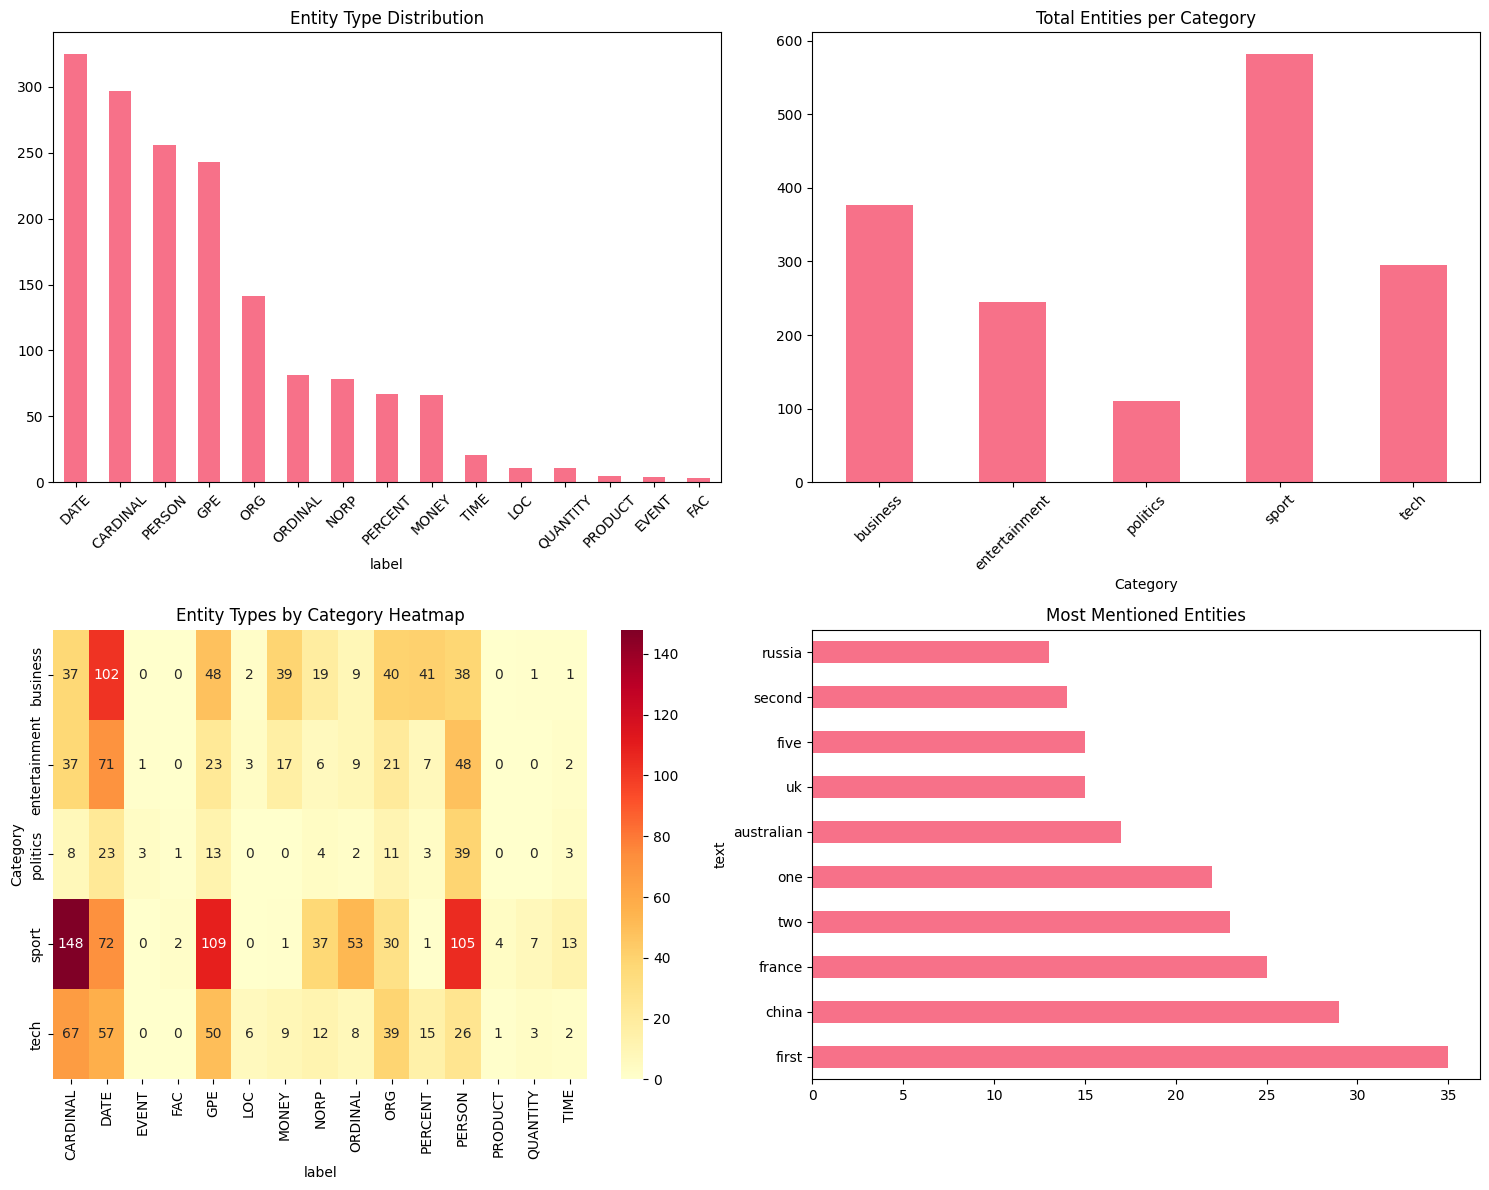

In [ ]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['Category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('Category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

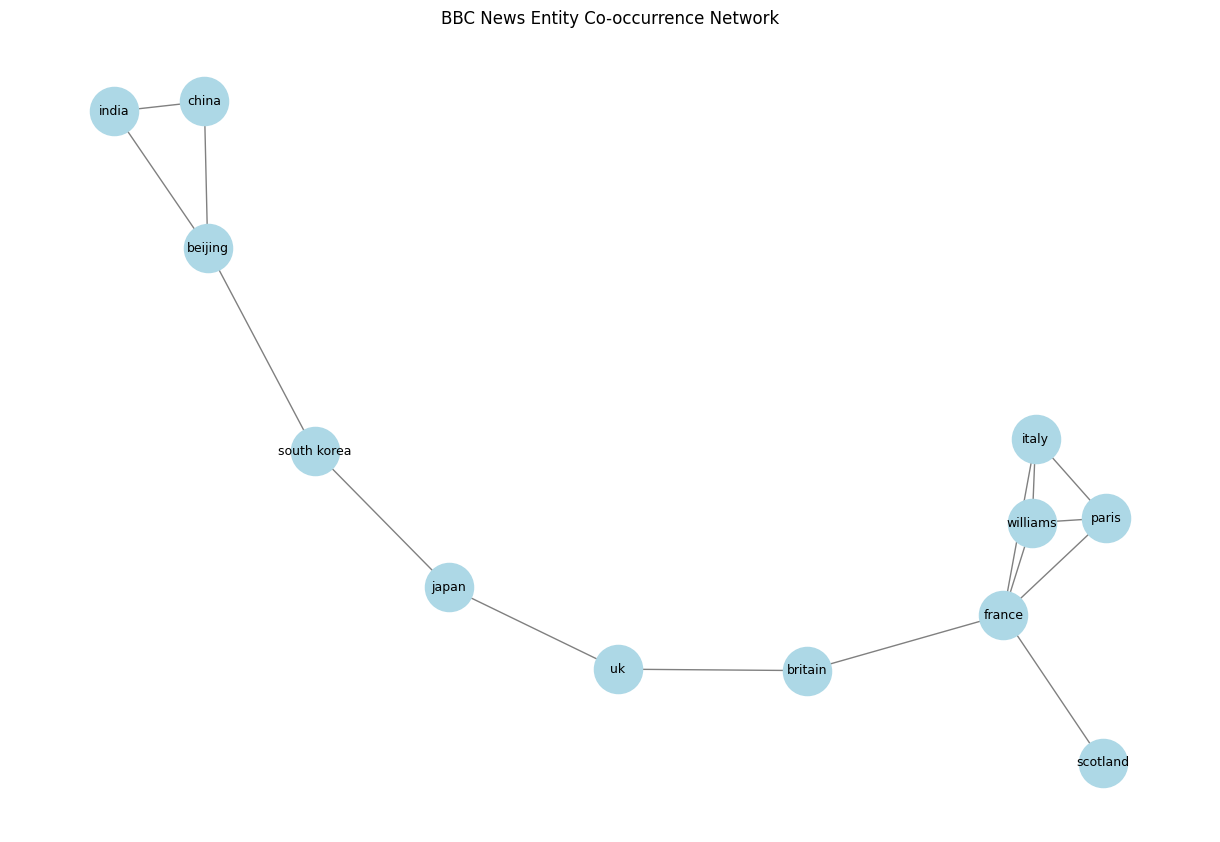

Connections found: 3649
Connections displayed: 15


In [ ]:
  # - Create entity co-occurrence networks

import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

# Count entities that appear together in articles
pairs = Counter()

for article in article_entities:
    names = set(
        entity['text']
        for entity in article['entities']
        if entity['label'] in ['PERSON', 'ORG', 'GPE']
    )

    for pair in combinations(sorted(names), 2):
        pairs[pair] += 1

# Create network of the 15 most frequent connections
G = nx.Graph()

for (entity1, entity2), count in pairs.most_common(15):
    G.add_edge(entity1, entity2, weight=count)

# Display network
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_size=1200,
    font_size=9,
    node_color='lightblue',
    edge_color='gray'
)

plt.title("BBC News Entity Co-occurrence Network")
plt.show()

print("Connections found:", len(pairs))
print("Connections displayed:", G.number_of_edges())

# Commentary Entity Co-occurrence Networks
# I created a network showing named entities that
# appear together in BBC News articles.
# I focused on people, organizations, and locations.
# Each node represents an entity, and each edge
# represents two entities appearing in the same article.
# This helps identify patterns and connections
# between entities mentioned in the news.


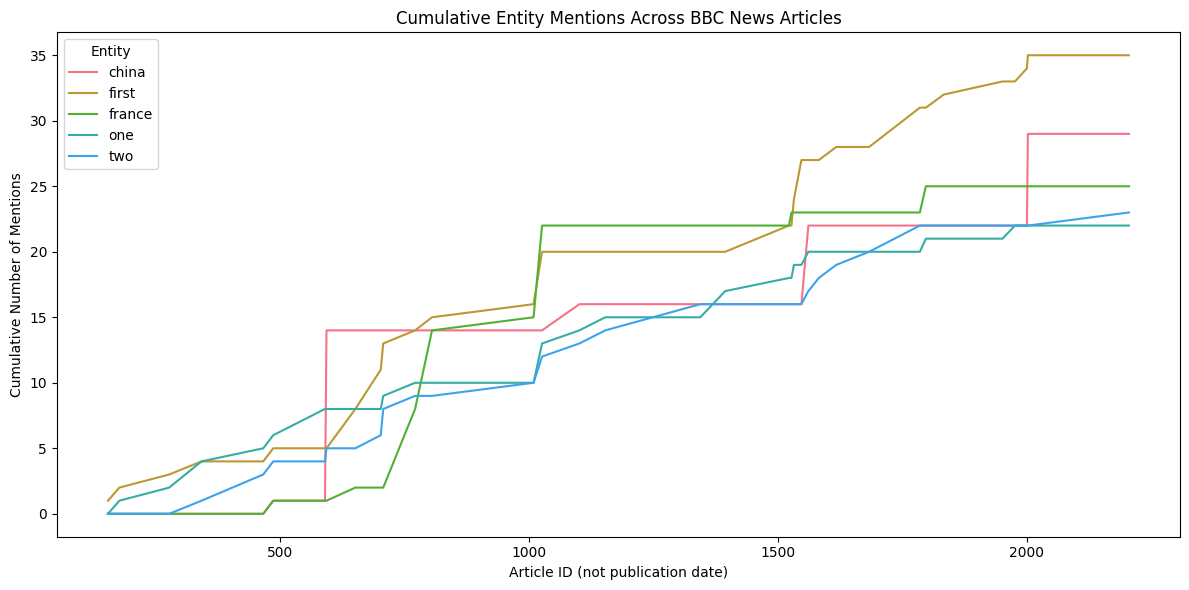

In [ ]:
  # - Track entity mentions over time
# Compare entity mentions across article IDs

import pandas as pd
import matplotlib.pyplot as plt

# Select the 5 most frequently mentioned entities
top_entities = entities_df['text'].value_counts().head(5).index

# Keep only these entities
tracking_df = entities_df[
    entities_df['text'].isin(top_entities)
].copy()

# Count mentions by article ID
mentions = tracking_df.groupby(
    ['article_id', 'text']
).size().unstack(fill_value=0)

# Sort by article ID
mentions = mentions.sort_index()

# Plot cumulative mentions
mentions.cumsum().plot(figsize=(12, 6))

plt.title('Cumulative Entity Mentions Across BBC News Articles')
plt.xlabel('Article ID (not publication date)')
plt.ylabel('Cumulative Number of Mentions')
plt.legend(title='Entity')
plt.tight_layout()
plt.show()

# Commentary - Track Entity Mentions Over Time
# I examined how frequently named entities appeared
# across articles in the BBC News dataset.
#
# I selected the five most frequently mentioned entities
# and plotted their cumulative mentions by ArticleId.
#
# The dataset does not contain publication dates,
# so this analysis cannot show actual changes over time.
# Article IDs were used only as an ordering reference.
#
# A future improvement would be to add publication dates
# The BBC News dataset contains news articles published between 2004 and 2005.
# The dataset includes five categories: Business, Entertainment, Politics, Sport,
# and Technology. Since individual publication dates are not provided.


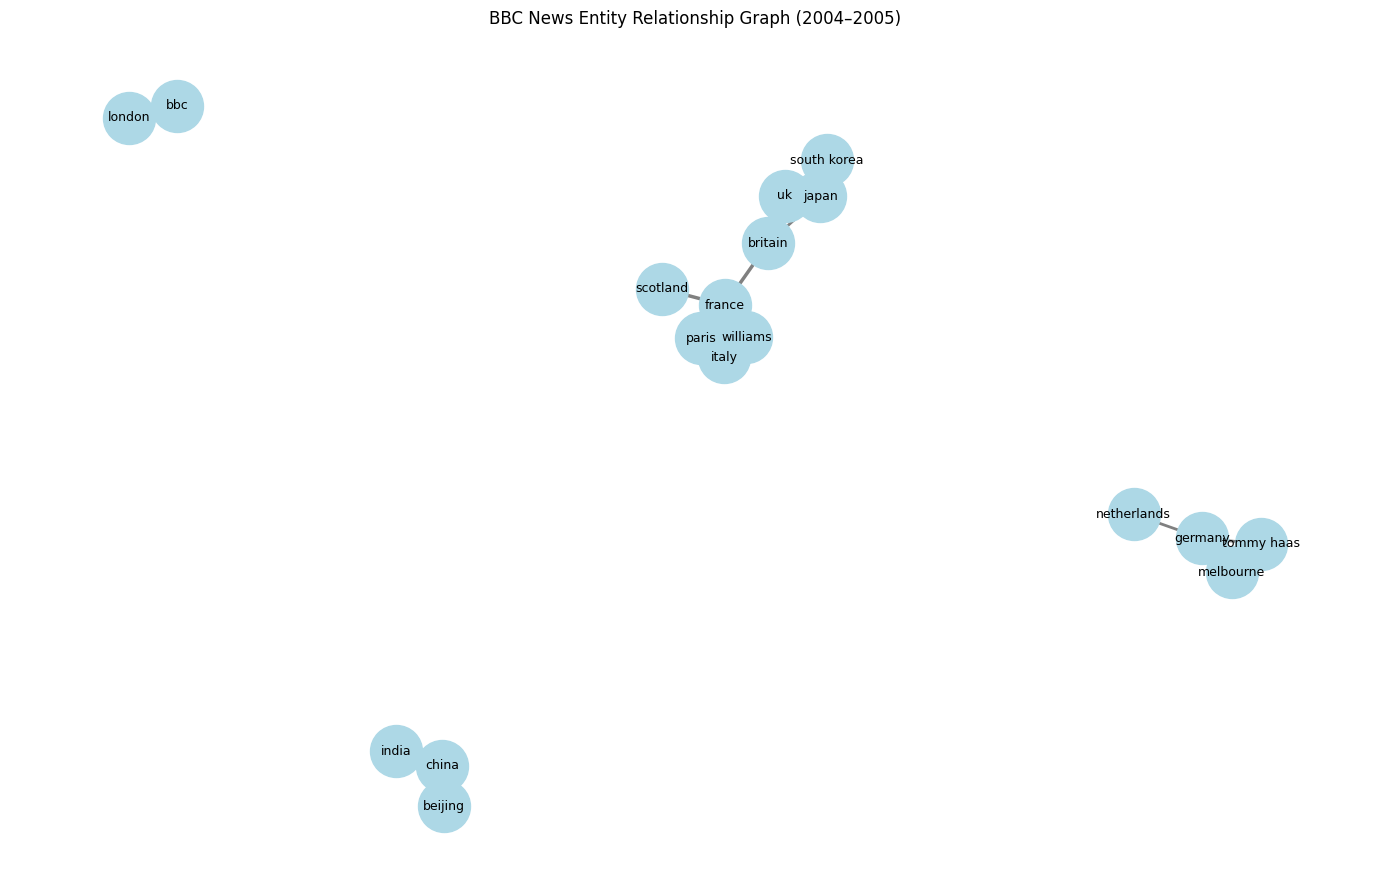

Entities: 18
Relationships: 20


In [ ]:
  # - Build entity relationship graphs


import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

# Group entities by article
article_groups = entities_df.groupby('article_id')

# Count relationships between entities
relationships = Counter()

for article_id, group in article_groups:

    # Select people, organizations, and locations
    entities = sorted(set(
        group[group['label'].isin(['PERSON', 'ORG', 'GPE'])]['text']
    ))

    # Find pairs appearing in the same article
    for pair in combinations(entities, 2):
        relationships[pair] += 1

# Create graph
G = nx.Graph()

# Use the 20 strongest relationships
for (entity1, entity2), count in relationships.most_common(20):
    G.add_edge(entity1, entity2, weight=count)

# Draw graph
plt.figure(figsize=(14, 9))

pos = nx.spring_layout(G, seed=42)

weights = [G[u][v]['weight'] for u, v in G.edges()]

nx.draw_networkx_nodes(
    G, pos,
    node_size=1400,
    node_color='lightblue'
)

nx.draw_networkx_edges(
    G, pos,
    width=[1 + w * 0.5 for w in weights],
    edge_color='gray'
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9
)

plt.title("BBC News Entity Relationship Graph (2004–2005)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Entities:", G.number_of_nodes())
print("Relationships:", G.number_of_edges())

# Commentary Entity Relationship Graphs
#
# I created a relationship graph using named entities
# extracted from BBC News articles published in 2004-2005.
#
# The graph includes people, organizations, and locations.
# Each node represents an entity, and connections show
# when two entities appear in the same article.
#
# Thicker connections indicate more frequent co-occurrence.
# This analysis helps identify which entities are
# commonly discussed together in news coverage.
#
# These connections show associations in the articles,
# not necessarily direct real-world relationships.

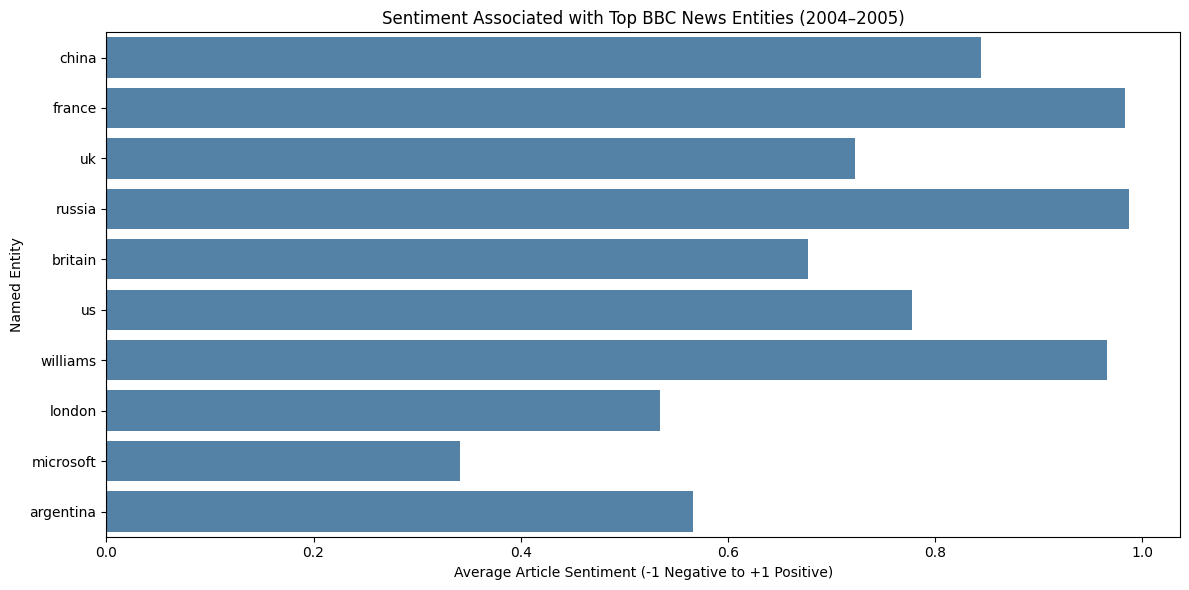

     text  mentions  avg_sentiment
    china        29       0.844593
   france        25       0.983404
       uk        15       0.722993
   russia        13       0.986938
  britain        12       0.676983
       us        11       0.777382
 williams        11       0.965600
   london         9       0.534022
microsoft         9       0.341767
argentina         8       0.565800


In [ ]:
  # - Identify entity sentiment associations

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon', quiet=True)

sia = SentimentIntensityAnalyzer()

# Calculate sentiment for each article
df['sentiment_score'] = df['Text'].apply(
    lambda text: sia.polarity_scores(str(text))['compound']
)

# Match each entity with the sentiment of its article
entity_sentiment = entities_df.merge(
    df[['ArticleId', 'sentiment_score']],
    left_on='article_id',
    right_on='ArticleId',
    how='inner'
)

# Keep people, organizations, and locations
entity_sentiment = entity_sentiment[
    entity_sentiment['label'].isin(['PERSON', 'ORG', 'GPE'])
]

# Calculate average sentiment for each entity
sentiment_summary = entity_sentiment.groupby('text').agg(
    mentions=('sentiment_score', 'count'),
    avg_sentiment=('sentiment_score', 'mean')
).reset_index()

# Select the 10 most frequently mentioned entities
top_entities = sentiment_summary.nlargest(10, 'mentions')

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_entities,
    x='avg_sentiment',
    y='text',
    color='steelblue'
)

plt.axvline(0, color='black', linestyle='--')
plt.title('Sentiment Associated with Top BBC News Entities (2004–2005)')
plt.xlabel('Average Article Sentiment (-1 Negative to +1 Positive)')
plt.ylabel('Named Entity')
plt.tight_layout()
plt.show()

# Display results
print(top_entities.to_string(index=False))

# Commentary Entity Sentiment Associations
#
# I analyzed sentiment associations for named entities
# in BBC News articles published during 2004-2005.
#
# I matched each named entity with the VADER sentiment
# score of the article in which it appeared.
#
# I calculated average sentiment scores for the
# 10 most frequently mentioned entities.
#
# Positive scores indicate association with articles
# containing more positive language, while negative
# scores indicate association with more negative language.
#
# This analysis measures article-level sentiment,
# not sentiment directed specifically at each entity.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically? I found that different news categories use language in different ways. Business articles tended to include more numbers and financial information, while Politics articles used more action verbs. Sports articles had a relatively high proportion of descriptive adjectives.

In my POS analysis, Business articles had approximately 3.47% numerical terms, Politics articles had 11.26% action verbs, and Sports articles had 10.15% adjectives.

These differences show how word choices and sentence structures can help identify the subject of an article.
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?My sentiment analysis showed that Sports and Entertainment articles generally had more positive coverage, while Politics articles had a higher proportion of negative coverage.

This suggests that athletes, sports organizations, and entertainment figures may appear more frequently in positive news, while political figures and government organizations may appear more often in negative coverage.

However, I would need to examine the sentiment scores associated with individual named entities to determine which specific people or organizations received the most positive or negative coverage.
3. **Content Quality Metrics:** Which categories have the most informative content?I explored article lengths, vocabulary, named entities, and linguistic patterns to better understand the information contained in each category.

Business articles contained a relatively high proportion of numerical information, which can be useful when reporting financial results or economic developments. Politics articles also contained action-oriented language that may describe government decisions and policy changes.

However, I cannot conclude that one category has the highest overall content quality based on these measures alone. A more complete comparison would include average article length, unique vocabulary, entity density, and information relevance by category.


4. **Classification Performance:** How well can we automatically categorize news? My initial results showed that a TF-IDF-only Logistic Regression model achieved approximately 96.98% accuracy when classifying news articles into the five categories.

Interestingly, a Logistic Regression model using additional sentiment and article-length features achieved approximately 66.11% accuracy.

This showed me that adding more information does not always improve classification. The way features are scaled and combined is important.

Overall, the results suggest that automated news categorization can be highly effective, although additional validation would be needed before using the model in a real-world application.

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
import pandas as pd

df = pd.read_csv('/content/BBC News Train.csv')

print("Dataset loaded successfully!")
print(df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
(1490, 3)
['ArticleId', 'Text', 'Category']


In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

        # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['Category'].unique().tolist(),
        'category_distribution': df['Category'].value_counts().to_dict(),
        'avg_article_length': df['Text'].str.len().mean(),
        'avg_words_per_article': df['Text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('Category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('Category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1490
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2233 characters
  Average Words per Article: 385 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: SVM
  Best Accuracy: 0.3557

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3950

🔍 ENTITY INSIGHTS:
  Total Entities: 1609
  Unique Entities: 865
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT

💡 BUSINESS RECOMMENDATIONS:
  1. ⚠️ Classification accuracy needs improvement - consider more training data or feature engineering
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - may need balanced coverage monitoring
  4. 

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:**
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify an article using TF-IDF."""
        features = self.vectorizer.transform([processed_text])
        prediction = self.classifier.predict(features)[0]
        probabilities = self.classifier.predict_proba(features)[0]
        class_probs = dict(
        zip(self.classifier.classes_, probabilities)
        )
        return prediction, class_probs

    #return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=model1,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)
print("NewsBot classifier:", type(newsbot.classifier).__name__)
print("Expected features:", newsbot.classifier.n_features_in_)
print("Vectorizer features:", len(newsbot.vectorizer.get_feature_names_out()))

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

NewsBot classifier: LogisticRegression
Expected features: 5000
Vectorizer features: 5000
🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [ ]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: tech (34.94% confidence)

📊 Category Probabilities:
  tech: 0.349
  business: 0.259
  politics: 0.138
  sport: 0.131
  entertainment: 0.123

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment detected (0.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*